# AdEase Case Study

## Problem Statement
AdEase is an ad-infrastructure company. It helps clients get the maximum clicks at minimum cost. An ad can only be shown where there is traffic, so page views are AdEase's raw inventory. If AdEase knows how many views a page group will get tomorrow, next week or next month, it can:

1. predict how many impressions are available to sell
2. decide which pages and languages deserve a client’s budget
3. price inventory sensibly and avoid over-promising impressions
4. time campaigns for high-traffic days

## Goal
To forecast daily page views for each language so Ad Ease can plan/optimise ad placement.

## Libraries

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import (
    mean_squared_error as mse,
    mean_absolute_error as mae,
    mean_absolute_percentage_error as mape
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

import warnings, itertools
warnings.filterwarnings("ignore")

TEST_DAYS = 60          # length of the hold-out window
SEASONAL_PERIOD = 7     # weekly cycle

## Data Loading

In [62]:
!gdown 1hmxDpGnzMdew_qWHeOkJp9NT_KQmCvCE

# Loading the dataset
df = pd.read_csv('/content/train_1.csv')
df.head()

,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,32.0,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,17.0,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,3.0,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,32.0,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0
4,52_Hz_I_Love_You_zh.wikipedia.org_all-access_s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,48.0,9.0,25.0,13.0,3.0,11.0,27.0,13.0,36.0,10.0


In [65]:
print(df.shape)
print('-------------------------------\n')
print(df.info())
print('-------------------------------\n')
print(f'Number of nan/null values in each column: \n{df.isna().sum()}')
print('-------------------------------\n')
print(f'Number of unique values in each column: \n{df.nunique()}')
print('-------------------------------\n')
print(f'Duplicate entries: \n{df.duplicated().value_counts()}')
print('-------------------------------\n')
print("Number of pages :", df.shape[0])
print('-------------------------------\n')
date_cols = list(df.columns[1:])
print("Number of days  :", len(date_cols))
print("Dtypes of date columns:", df[date_cols].dtypes.value_counts().to_dict())

(145063, 551)
-------------------------------

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145063 entries, 0 to 145062
Columns: 551 entries, Page to 2016-12-31
dtypes: float64(550), object(1)
memory usage: 609.8+ MB
None
-------------------------------

Number of nan/null values in each column: 
Page              0
2015-07-01    20740
2015-07-02    20816
2015-07-03    20544
2015-07-04    20654
              ...  
2016-12-27     3701
2016-12-28     3822
2016-12-29     3826
2016-12-30     3635
2016-12-31     3465
Length: 551, dtype: int64
-------------------------------

Number of unique values in each column: 
Page          145063
2015-07-01      6898
2015-07-02      6823
2015-07-03      6707
2015-07-04      6995
               ...  
2016-12-27      8938
2016-12-28      8819
2016-12-29      8761
2016-12-30      8733
2016-12-31      8826
Length: 551, dtype: int64
-------------------------------

Duplicate entries: 
False    145063
Name: count, dtype: int64
-------------------------

In [ ]:
df[date_cols].describe().T.iloc[[0, 100, 300, -1]]

,count,mean,std,min,25%,50%,75%,max
2015-07-01,124323.0,1195.856567,72753.518671,0.0,13.0,109.0,524.0,20381245.0
2015-10-09,127292.0,1283.243896,67698.439892,0.0,16.0,129.0,620.0,18440817.0
2016-04-26,135384.0,1393.451752,63029.587984,0.0,20.0,158.0,724.0,17808242.0
2016-12-31,141598.0,1478.282137,88735.672589,0.0,21.0,136.0,561.0,26149541.0


Observations:
1. There are 145063 entries with 551 columns, i.e. 145063 wikipedia pages with views for 550 days
2. There are null/missing values in each of the dates
3. There are no duplicates
4. There are 145063 unique wikipedia pages

In [ ]:
!gdown 1C6SnDdzzdWLRxO3L4JaNZkEI8rPsRoWG

# Loading the exog file that has flags for each date that indicate whether or not there was a campaign or other noteworthy event.
exog = pd.read_csv('/content/Exog_Campaign_eng')
exog.head()

,Exog
0,0
1,0
2,0
3,0
4,0


In [66]:
print(exog.shape)
print('-------------------------------\n')
print(exog.info())
print('-------------------------------\n')
print(f'Number of nan/null values in each column: \n{exog.isna().sum()}')
print('-------------------------------\n')
print(f'Number of unique values in each column: \n{exog.nunique()}')
print('-------------------------------\n')
print(f'Duplicate entries: \n{exog.duplicated().value_counts()}')

(550,)
-------------------------------

<class 'pandas.core.series.Series'>
DatetimeIndex: 550 entries, 2015-07-01 to 2016-12-31
Freq: D
Series name: Exog
Non-Null Count  Dtype
--------------  -----
550 non-null    int64
dtypes: int64(1)
memory usage: 8.6 KB
None
-------------------------------

Number of nan/null values in each column: 
0
-------------------------------

Number of unique values in each column: 
2
-------------------------------

Duplicate entries: 
Exog
True     548
False      2
Name: count, dtype: int64


Observations:
1. There are 550 entries corresponding to 550 days in the previous dataset
2. There are no missing values.
3. There are 2 unique values only - 1 and 0

## Exploratory Data Analysis

### Missing values treatment

Total NaN cells            : 6,192,931 (7.76% of all cells)
Pages with >=1 NaN         : 27,786 (19.2%)
Pages that are ALL NaN     : 652
Pages whose series starts late (leading NaN): 20,088


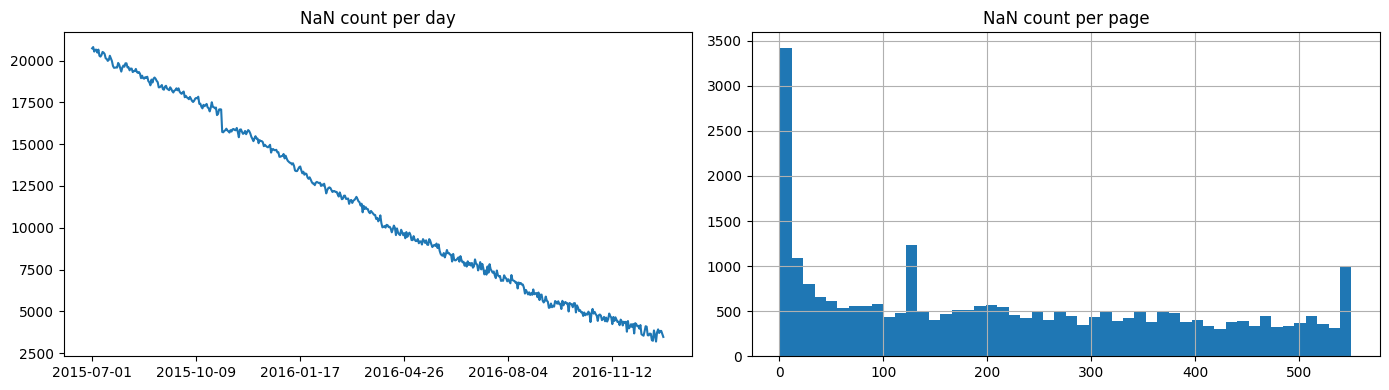

In [67]:
nan_per_page = df[date_cols].isna().sum(axis=1)
nan_per_day = df[date_cols].isna().sum()
first_valid = df[date_cols].notna().values.argmax(axis=1)
all_nan = nan_per_page == len(date_cols)

print(f"Total NaN cells            : {df[date_cols].isna().sum().sum():,} "
      f"({df[date_cols].isna().mean().mean():.2%} of all cells)")
print(f"Pages with >=1 NaN         : {(nan_per_page > 0).sum():,} ({(nan_per_page > 0).mean():.1%})")
print(f"Pages that are ALL NaN     : {all_nan.sum():,}")
print(f"Pages whose series starts late (leading NaN): {((first_valid > 0) & ~all_nan).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
nan_per_day.plot(ax=ax[0]); ax[0].set_title("NaN count per day")
nan_per_page[nan_per_page > 0].hist(bins=50, ax=ax[1]); ax[1].set_title("NaN count per page")
plt.tight_layout()
plt.show()

Observations:
1. Missing values make up 7.76% of all cells and affect 19.2% of the pages. They are concentrated at the start of the window.
2. 20,088 pages have leading NaNs (series starts late) and 652 pages have no data at all.

Treatment:
1. Will drop the 652 pages that are 100% NaN, since they carry no information.
2. Interpolate interior gaps linearly, page by page.
3. Fill leading/trailing NaNs with the nearest observed value.

Why not choosing the other alternatives:
- Fill with 0: the language average would rise over time only because more pages "appear", which creates a false upward trend.
- Fill with the mean: page sizes range from 0 to millions of views, so one mean ignores each page's scale and its own time pattern.
- Drop pages with any NaN: this removes 19.2% of the pages.

In [68]:
df = df.loc[~all_nan].reset_index(drop=True)
vals = df[date_cols].astype("float32").interpolate(axis=1, method="linear", limit_direction="both")
df[date_cols] = vals
assert df[date_cols].isna().sum().sum() == 0

### Feature Extracting from Page column

In [69]:
df['Page'].sample(10)

,Page
50509,Der_Herr_der_Ringe:_Die_Rückkehr_des_Königs_(F...
16681,"Глинка,_Михаил_Иванович_ru.wikipedia.org_mobil..."
117579,Landtagswahl_in_Baden-Württemberg_2016_de.wiki...
20369,VisualEditor_www.mediawiki.org_all-access_all-...
3829,又，吳海英_zh.wikipedia.org_all-access_spider
61890,东海舰队_zh.wikipedia.org_desktop_all-agents
6761,Niantic_(entreprise)_fr.wikipedia.org_desktop_...
32328,Anthony_Hopkins_en.wikipedia.org_all-access_sp...
142623,Leonardo_DiCaprio_es.wikipedia.org_all-access_...
73095,Enzo_Amore_en.wikipedia.org_mobile-web_all-agents


Format of page: NAME _ LANGUAGE.wikipedia.org _ ACCESS TYPE _ ACCESS ORIGIN.
This gives the information about the page name, domain, device type, request origin

In [70]:
# Parse the Page column in one vectorized pass
pattern = (
    r"^(?P<name>.+)_(?P<project>[a-z\-]+)\.(?P<domain>wikipedia|wikimedia|mediawiki)\.org_"
    r"(?P<access_type>all-access|desktop|mobile-web)_(?P<access_origin>all-agents|spider)$"
)
meta = df["Page"].str.extract(pattern)
unmatched = meta["domain"].isna()
print("Pages not matched by regex:", unmatched.sum())

Pages not matched by regex: 0


In [71]:
# Language: use the project code only for *.wikipedia.org- commons/www are "media", failed parses are marked as "unknown"
meta["lang_code"] = (
    meta["project"]
    .where(meta["domain"].eq("wikipedia"), "media")
    .mask(unmatched, "unknown")
)

lang_names = {
    "en": "English", "de": "German", "fr": "French", "es": "Spanish",
    "ru": "Russian", "ja": "Japanese", "zh": "Chinese",
    "media": "Media (Commons/MediaWiki)", "unknown": "Unknown",
}
# fall back to the raw code so nothing becomes NaN
meta["language"] = meta["lang_code"].map(lang_names).fillna(meta["lang_code"])

In [72]:
df = pd.concat([df, meta[["name", "language", "access_type", "access_origin"]]], axis=1)

% of pages in different languages
language
English                      16.63
Japanese                     14.08
German                       12.77
French                       12.30
Media (Commons/MediaWiki)    12.28
Chinese                      11.84
Russian                      10.38
Spanish                       9.72
Name: count, dtype: float64


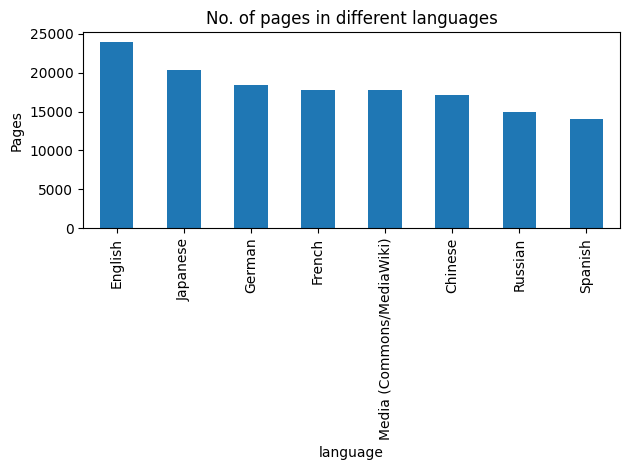

In [73]:
lang_counts = df["language"].value_counts()
print("% of pages in different languages")
print((lang_counts / lang_counts.sum() * 100).round(2))

lang_counts.plot(kind="bar", title="No. of pages in different languages")
plt.ylabel("Pages")
plt.tight_layout()
plt.show()

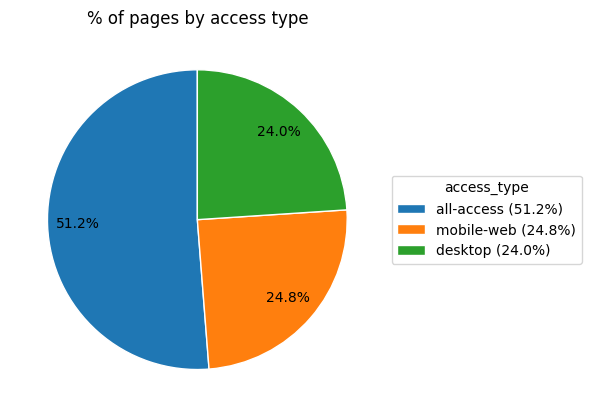

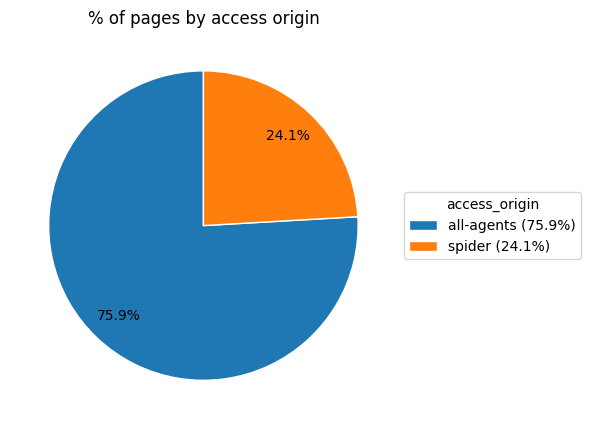

In [74]:
def pie_with_legend(series, title):
    counts = series.value_counts()
    pct = counts / counts.sum() * 100
    fig, ax = plt.subplots(figsize=(6, 6))
    wedges, _, autotexts = ax.pie(
        counts,
        labels=None,
        autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
        startangle=90,
        pctdistance=0.8,
        wedgeprops={"edgecolor": "white"},
    )
    # legend carries the names and exact percentages
    ax.legend(wedges, [f"{k} ({v:.1f}%)" for k, v in pct.items()],
              title=series.name, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(title)
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

pie_with_legend(df["access_type"], "% of pages by access type")
pie_with_legend(df["access_origin"], "% of pages by access origin")

Observations:
1. Maximum number of pages are in in English language (16.63%).
2. Maximum number of pages have all-access access type (51.2%).
3. Maximum number of pages have agents access origin (75.9%).

## Aggregation and Pivoting

Forecasts are needed per language, so grouping by language and aggregating over pages. After aggregation the data is pivoted to the standard format i.e. one row per date, one column per language.

In [75]:
# Aggregate per language
g = df.groupby("language")[date_cols]
lang_mean, lang_sum = [t.T.set_axis(pd.to_datetime(date_cols)).rename_axis("date").asfreq("D")
                       for t in (g.mean(), g.sum())]
LANGS = list(lang_mean.columns)
print(lang_mean.index.min(), "->", lang_mean.index.max(), "| days:", len(lang_mean))

2015-07-01 00:00:00 -> 2016-12-31 00:00:00 | days: 550


In [76]:
# Campaign variable
exog = (exog["Exog"] if isinstance(exog, pd.DataFrame) else exog).astype(int)
exog.index = lang_mean.index
assert len(exog) == len(lang_mean), "exog length must match the page-view data"
campaign = exog[exog == 1].index
print("Campaign days:", len(campaign), "of", len(exog))

Campaign days: 54 of 550


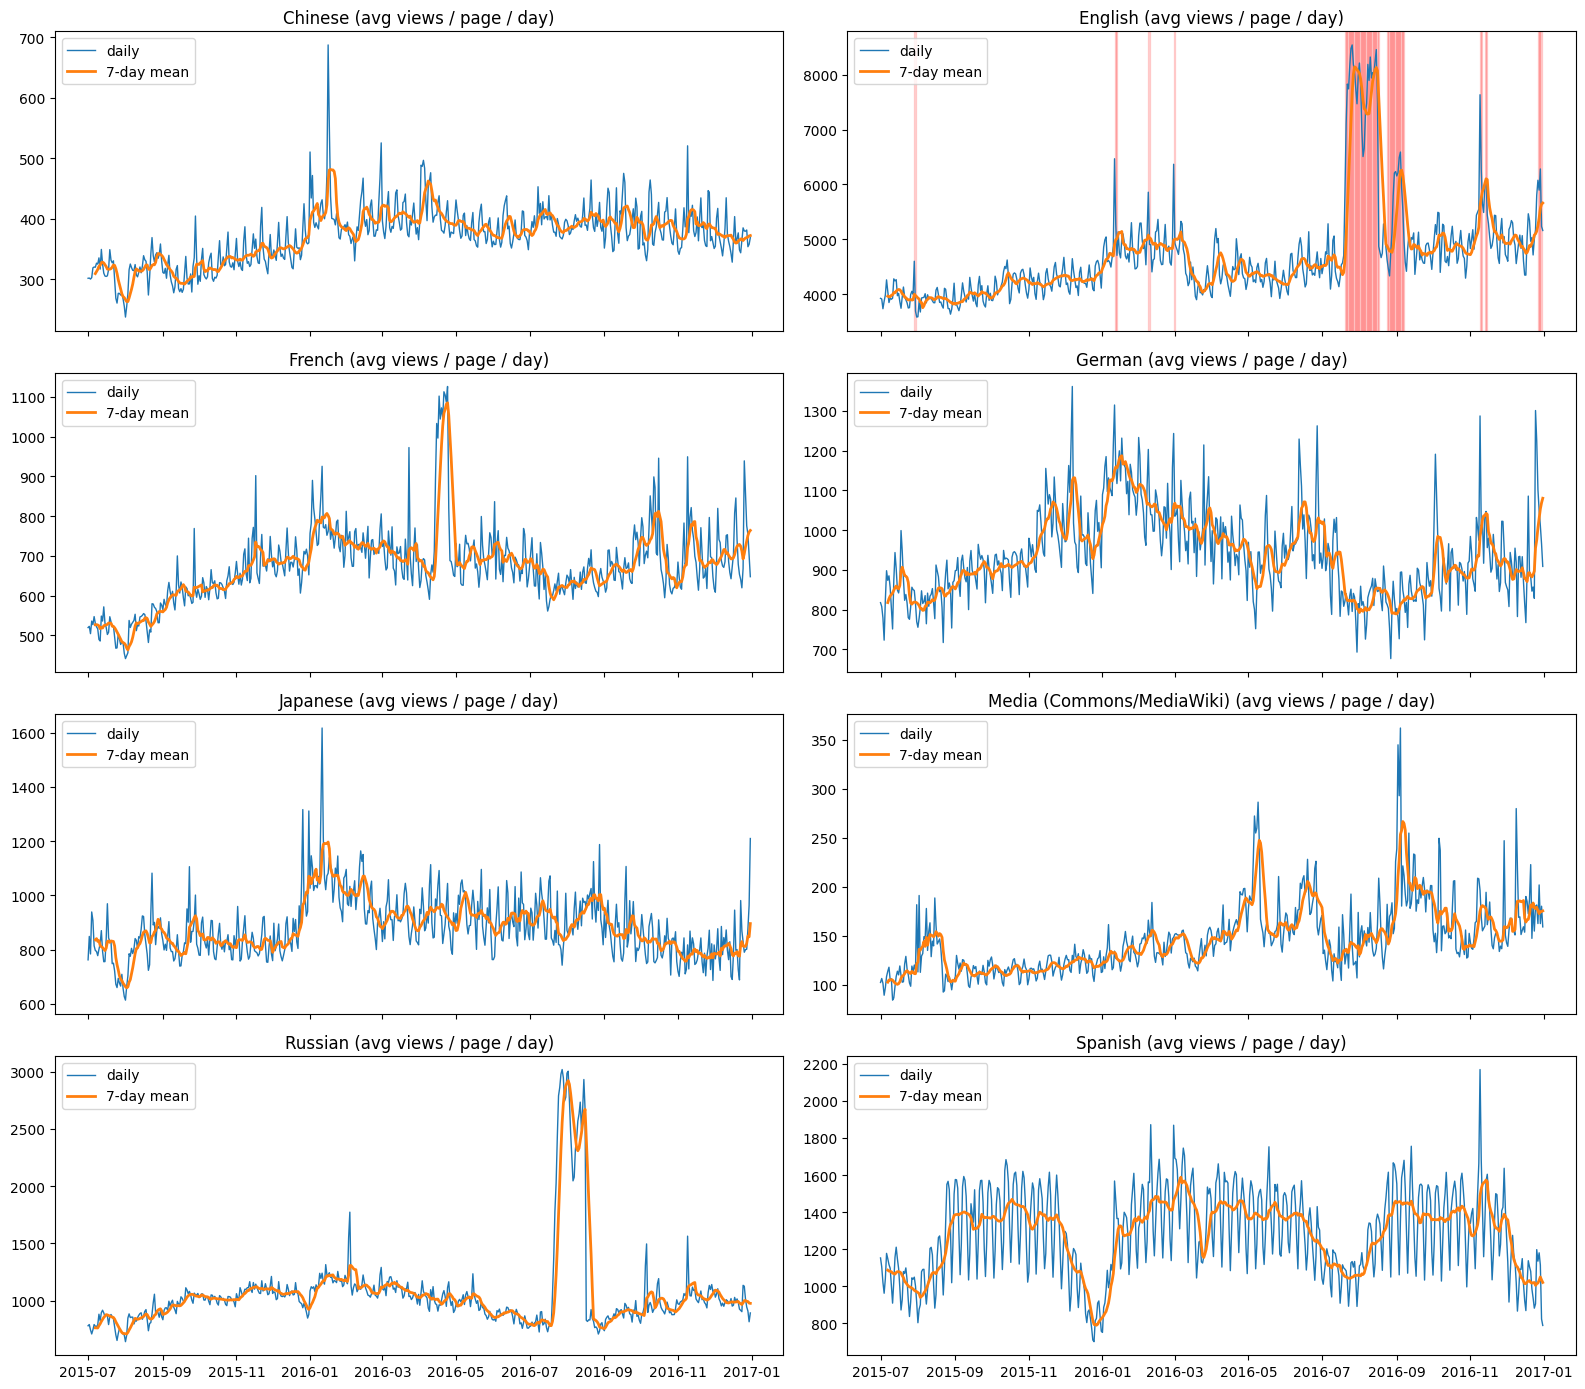

In [77]:
# Per-language panels with 7-day rolling mean
fig, axes = plt.subplots(int(np.ceil(len(LANGS) / 2)), 2, figsize=(16, 14), sharex=True)
for ax, lang in zip(axes.ravel(), LANGS):
    ax.plot(lang_mean[lang], lw=1, label="daily")
    ax.plot(lang_mean[lang].rolling(7).mean(), lw=2, label="7-day mean")
    ax.set(title=f"{lang} (avg views / page / day)"); ax.legend(loc="upper left")
    if lang == "English":
        for d in campaign: ax.axvspan(d, d + pd.Timedelta(days=1), color="red", alpha=.15)
for ax in axes.ravel()[len(LANGS):]: ax.set_visible(False)
plt.tight_layout()
plt.show()

In [78]:
# Summary table
tot = lang_sum.sum()
summary = pd.DataFrame({
    "mean_views_per_page": lang_mean.mean(),
    "total_views_billion": tot / 1e9,
    "share_%": tot / tot.sum() * 100,
    "volatility(CV)": lang_mean.std() / lang_mean.mean(),
    "peak_date": lang_mean.idxmax(),
}).sort_values("mean_views_per_page", ascending=False)
display(summary.round(2).T)

language,English,Spanish,Russian,German,Japanese,French,Chinese,Media (Commons/MediaWiki)
mean_views_per_page,4698.939941,1279.390015,1060.790039,938.580017,881.780029,673.669983,371.399994,146.240005
total_views_billion,62.049999,9.88,8.75,9.52,9.86,6.58,3.49,1.43
share_%,55.619999,8.86,7.84,8.53,8.84,5.9,3.13,1.28
volatility(CV),0.19,0.18,0.35,0.12,0.13,0.15,0.13,0.25
peak_date,2016-07-26 00:00:00,2016-11-09 00:00:00,2016-07-28 00:00:00,2015-12-07 00:00:00,2016-01-11 00:00:00,2016-04-24 00:00:00,2016-01-16 00:00:00,2016-09-04 00:00:00


Observations:
1. English language dominates the data. It has 16.6% of the pages but 55.6% of all views (62 billion views), about 4,700 views per page per day. Spanish is next at about 1,280 and Media (Commons/MediaWiki) is the lowest at about 146.
2. Every language has a weekly cycle. It is clearest in Spanish, where the daily line swings sharply every week and the level dips around the turn of the year and in mid-2016.
3. English shows a campaign effect. From July to September 2016 the 7-day average jumps from about 4,500 to about 8,000, exactly where the campaign days (red shading) cluster. Isolated campaign days elsewhere show smaller bumps.
4. Other languages have one-off spikes with no campaign flag. Russian (July-August 2016, roughly 3x normal), French (April 2016), and Chinese and Japanese (January-February 2016). We have no exogenous variable for these.
5. Volatility: Russian is the most volatile (CV 0.35) because of its summer spike, followed by Media (0.25). German, Japanese and Chinese are the steadiest (CV about 0.12-0.13).
6. Why English is so much larger: The maximum views for a single page on a single day exceed 17 million, while the median page gets about 100-160. A small number of very popular English pages therefore drive the average.

### Distribution of views across pages and weekly pattern by language

,mean_per_page,median_per_page,top10_pages_share_%
language,,,
English,4698.899902,1018.299988,43.799999
Spanish,1279.400024,645.500000,20.600000
Russian,1060.800049,454.799988,30.400000
German,938.599976,277.899994,39.599998
Japanese,881.799988,441.700012,7.000000
French,673.700012,258.600006,33.500000
Chinese,371.399994,175.000000,11.100000
Media (Commons/MediaWiki),146.199997,18.500000,29.900000


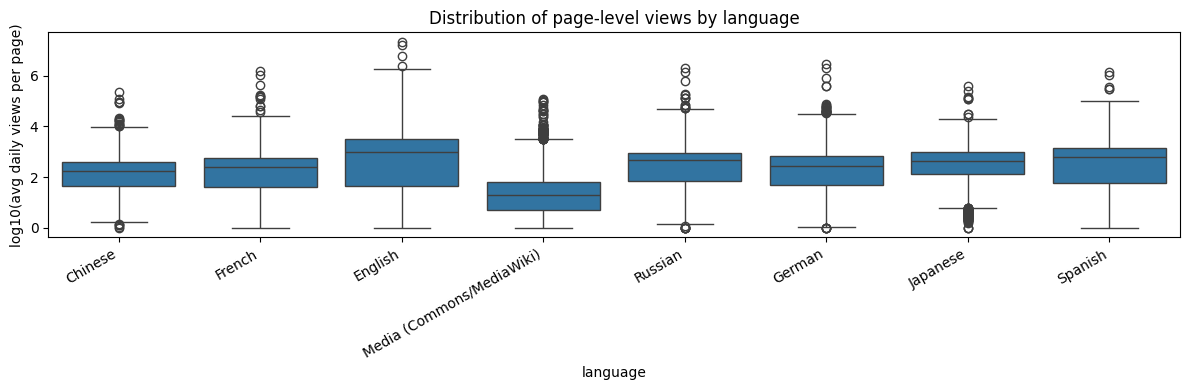

In [80]:
# How concentrated are the views?
page_avg = df[date_cols].mean(axis=1)
page_total = df[date_cols].sum(axis=1)

lang_stats = pd.DataFrame({
    "mean_per_page": page_avg.groupby(df["language"]).mean(),
    "median_per_page": page_avg.groupby(df["language"]).median(),
    "top10_pages_share_%": page_total.groupby(df["language"]).apply(lambda s: s.nlargest(10).sum() / s.sum() * 100),
}).round(1)
display(lang_stats.sort_values("mean_per_page", ascending=False))

plt.figure(figsize=(12, 4))
sns.boxplot(x=df["language"], y=np.log10(page_avg + 1))
plt.ylabel("log10(avg daily views per page)")
plt.xticks(rotation=30, ha="right")
plt.title("Distribution of page-level views by language")
plt.tight_layout()
plt.show()

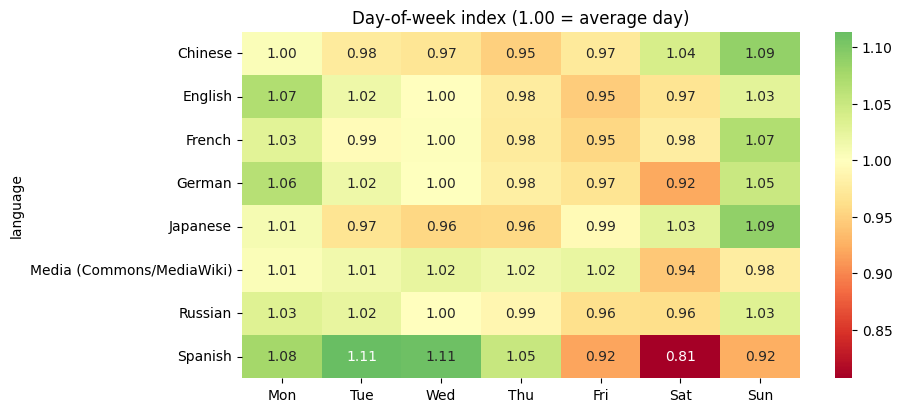

In [81]:
# Day-of-week index: average for that weekday / language's overall average (1.00 = average day)
wk = (lang_mean.groupby(lang_mean.index.dayofweek).mean() / lang_mean.mean()).T
wk.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(9, 4.5))
sns.heatmap(wk, annot=True, fmt=".2f", cmap="RdYlGn", center=1)
plt.title("Day-of-week index (1.00 = average day)")
plt.show()

## Stationarity, decomposition, differencing, ACF / PACF

In [82]:
def adfuller_test(y):
    p = adfuller(y.dropna())[1]
    print(f"p-value = {p:.4f} -> The time series is {'stationary' if p < 0.05 else 'not stationary'}")

In [83]:
# ADF test for every language
for c in LANGS:
    print(c)
    adfuller_test(lang_mean[c])
    print()

y_en = lang_mean["English"]

Chinese
p-value = 0.2611 -> The time series is not stationary

English
p-value = 0.1103 -> The time series is not stationary

French
p-value = 0.0300 -> The time series is stationary

German
p-value = 0.1402 -> The time series is not stationary

Japanese
p-value = 0.0295 -> The time series is stationary

Media (Commons/MediaWiki)
p-value = 0.0071 -> The time series is stationary

Russian
p-value = 0.0014 -> The time series is stationary

Spanish
p-value = 0.0368 -> The time series is stationary



Observations (ADF test at 5%):
1. Not stationary in levels: Chinese (p = 0.26), English (p = 0.11) and German (p = 0.14).
2. Stationary in levels: French, Japanese, Spanish, Russian and Media. French, Japanese and Spanish are only just below 0.05 (0.030, 0.0295, 0.037), so this is a weak result, and a visible weekly cycle remains in all of them.
3. After one difference (d = 1) the English series is stationary (p < 0.0001), and adding a seasonal difference (D = 1, s = 7) keeps it stationary.

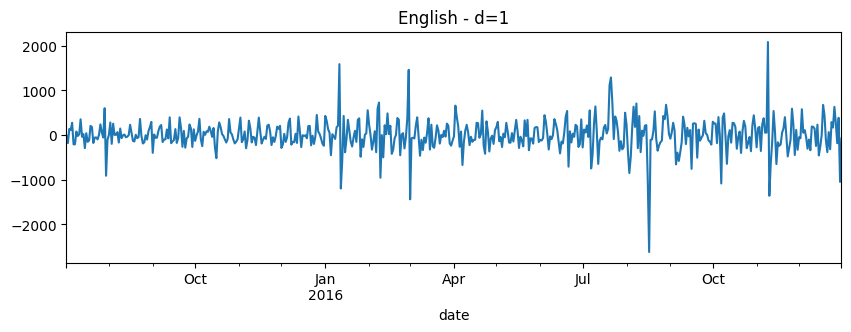

p-value = 0.0000 -> The time series is stationary


In [85]:
# First difference
y_en.diff().dropna().plot(figsize=(10, 3), title="English - d=1"); plt.show()
adfuller_test(y_en.diff())

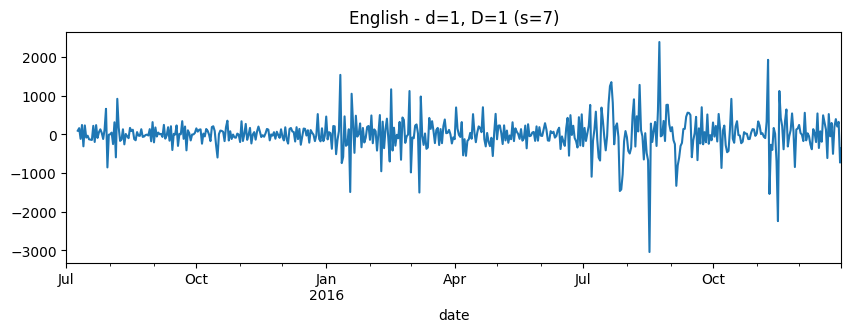

p-value = 0.0000 -> The time series is stationary


In [87]:
# Seasonal difference on top of first difference
y_en.diff().diff(7).plot(figsize=(10, 3), title="English - d=1, D=1 (s=7)"); plt.show()
adfuller_test(y_en.diff().diff(7))

After removing trend, the Augmented Dickey-Fuller test says that the time series is stationary.

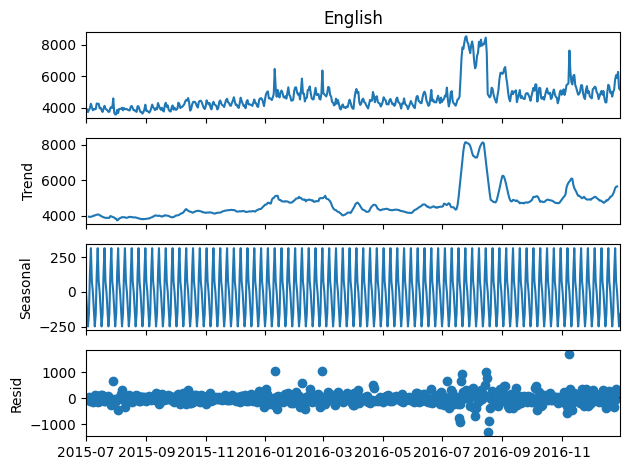

In [88]:
# Decomposition
decom = seasonal_decompose(y_en, period=7)
decom.plot()
plt.tight_layout()
plt.show()

### ACF / PACF as per the guideline
PACF on the original series (no de-trending or de-seasoning) and ACF on the de-trended and de-seasoned series (d = 1, D = 1, s = 7). These plots set the ranges for p, q, P and Q in the grid search below.

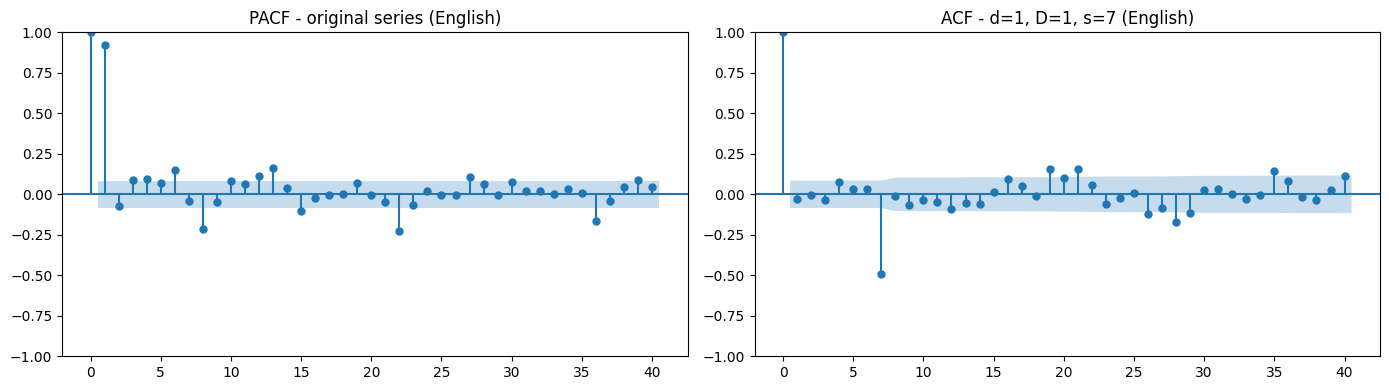

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_pacf(y_en, lags=40, ax=ax[0], method="ywm")
ax[0].set_title("PACF - original series (English)")
plot_acf(y_en.diff().diff(SEASONAL_PERIOD).dropna(), lags=40, ax=ax[1])
ax[1].set_title("ACF - d=1, D=1, s=7 (English)")
plt.tight_layout()
plt.show()

Observations:
1. **PACF of the original series:** a very strong spike at lag 1 (about 0.9) and little beyond it. This points to a series close to a unit root, which is why d = 1 is needed, and to a small AR order (p = 0 or 1).
2. **ACF of the d = 1, D = 1 series:** a single large negative spike at the seasonal lag 7 (about -0.5) and nothing at lags 1-6. This suggests one seasonal MA term (Q = 1) and a small non-seasonal q (0 or 1).
3. This agrees with the grid search, which chose (1,1,1)(0,1,1,7) for English.

## Model Building

In [91]:
# Creating a function to print values of all error metrics.
def performance(actual, predicted, print_metrics=True):
    MAE = round(mae(actual, predicted), 3)
    RMSE = round(mse(actual, predicted) ** 0.5, 3)
    MAPE = round(mape(actual, predicted) * 100, 3)
    if print_metrics:
        print("MAE :", MAE)
        print("RMSE :", RMSE)
        print("MAPE:", MAPE)
    return MAE, RMSE, MAPE

In [92]:
def plot_forecast(pred, title):
    plt.figure(figsize=(12, 4))
    y_en[-120:].plot(label="Actual")
    pred.plot(label="Forecast", color="red", linestyle="dashed", marker=".")
    plt.legend(loc="upper right")
    plt.title(title)
    plt.show()

In [94]:
# Train / test split
y_en = lang_mean["English"]
y_train, y_test = y_en[:-TEST_DAYS], y_en[-TEST_DAYS:]
exog_train, exog_test = exog[:-TEST_DAYS], exog[-TEST_DAYS:]
scores = {}

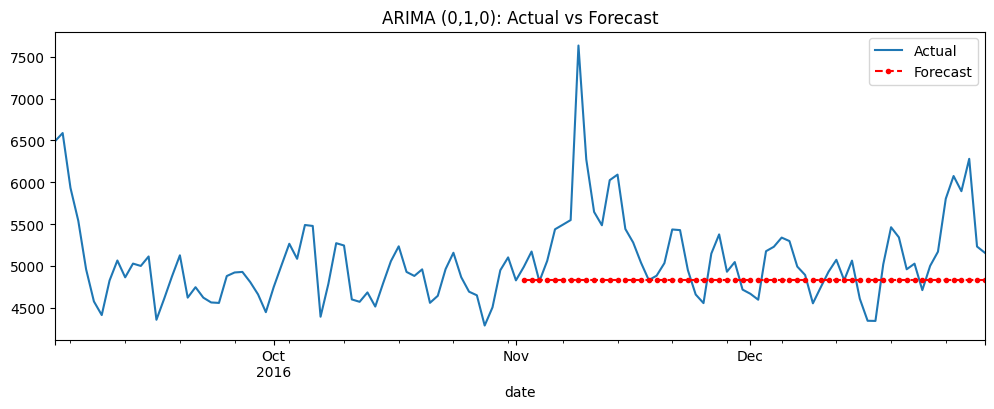

MAE : 463.317
RMSE : 660.099
MAPE: 8.263


In [95]:
# ARIMA Model
arima_fit = ARIMA(y_train, order=(0, 1, 0)).fit()
arima_pred = arima_fit.forecast(steps=TEST_DAYS)
plot_forecast(arima_pred, "ARIMA (0,1,0): Actual vs Forecast")
scores["ARIMA"] = performance(y_test, arima_pred)

In [96]:
# SARIMA Model
p, d, q, P, D, Q = 1, 1, 1, 1, 1, 1
sarima_fit = SARIMAX(y_train, order=(p, d, q),
                     seasonal_order=(P, D, Q, SEASONAL_PERIOD),
                     initialization="approximate_diffuse").fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=TEST_DAYS)
scores["SARIMA"] = performance(y_test, sarima_pred)

MAE : 434.128
RMSE : 585.174
MAPE: 8.151


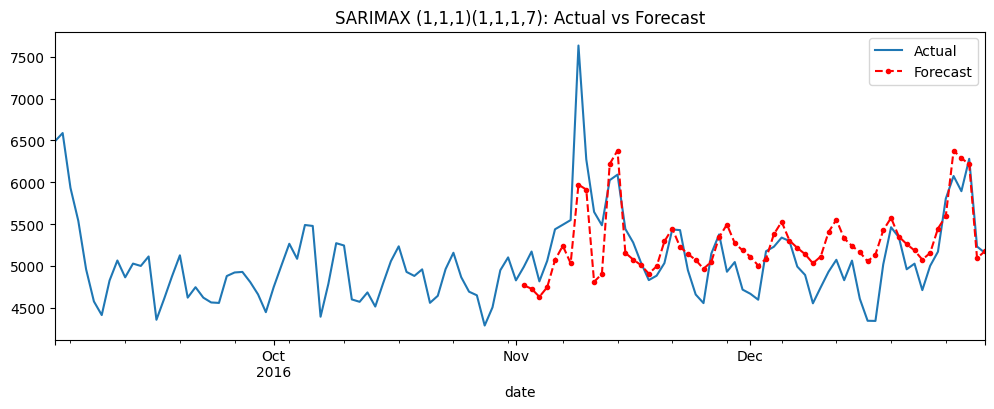

MAE : 316.663
RMSE : 408.956
MAPE: 6.101


In [97]:
# SARIMAX Model
sarimax_fit = SARIMAX(y_train, exog=exog_train, order=(p, d, q),
                      seasonal_order=(P, D, Q, SEASONAL_PERIOD),
                      initialization="approximate_diffuse").fit(disp=False)
sarimax_pred = sarimax_fit.forecast(steps=TEST_DAYS, exog=exog_test)
plot_forecast(sarimax_pred, f"SARIMAX ({p},{d},{q})({P},{D},{Q},{SEASONAL_PERIOD}): Actual vs Forecast")
scores["SARIMAX"] = performance(y_test, sarimax_pred)

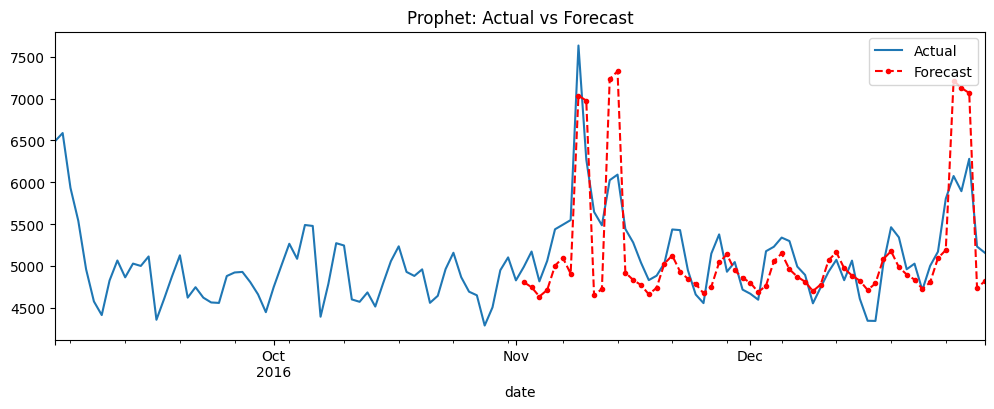

MAE : 352.202
RMSE : 468.849
MAPE: 6.438


In [98]:
# Prophet Model
train_df = pd.DataFrame({"ds": y_train.index, "y": y_train.values, "exog": exog_train.values})
test_df = pd.DataFrame({"ds": y_test.index, "exog": exog_test.values})

prophet = Prophet(interval_width=0.95, daily_seasonality=False,
                  weekly_seasonality=True, yearly_seasonality=False)
prophet.add_regressor("exog")
prophet.fit(train_df)
forecast = prophet.predict(test_df)
prophet_pred = pd.Series(forecast["yhat"].values, index=y_test.index)
plot_forecast(prophet_pred, "Prophet: Actual vs Forecast")
scores["Prophet"] = performance(y_test, prophet_pred)

In [99]:
# Comparison table
results = pd.DataFrame(scores, index=["MAE", "RMSE", "MAPE"]).T.sort_values("MAPE")
display(results)

,MAE,RMSE,MAPE
SARIMAX,316.663,408.956,6.101
Prophet,352.202,468.849,6.438
SARIMA,434.128,585.174,8.151
ARIMA,463.317,660.099,8.263


English: SARIMAX (with the campaign variable) has the lowest error: MAPE 6.10% against 8.15% for SARIMA with the same orders, i.e. MAE falls from 434 to 317 (about 27%). Prophet with the campaign regressor is close behind at 6.44%. Plain ARIMA(0,1,0) is the weakest at 8.26%. The campaign variable is clearly useful.

Running Chinese
Running English
Running French
Running German
Running Japanese
Running Media (Commons/MediaWiki)
Running Russian
Running Spanish


model,ARIMA,Prophet,Prophet(exog),SARIMA,SARIMAX,SeasonalNaive
language,,,,,,
Chinese,5.806000,5.354000,nan,5.270000,nan,4.501000
English,8.718000,11.658000,6.438000,8.488000,6.064000,9.223000
French,8.636000,6.481000,nan,6.506000,nan,11.142000
German,7.631000,8.411000,nan,6.428000,nan,7.497000
Japanese,6.807000,8.240000,nan,5.762000,nan,7.411000
Media (Commons/MediaWiki),12.217000,14.543000,nan,12.675000,nan,16.468000
Russian,6.926000,9.074000,nan,7.706000,nan,10.054000
Spanish,14.533000,21.028000,nan,13.475000,nan,16.770000


,model,MAPE,RMSE,naive_MAPE,gain_vs_naive_%,within_4_8%
language,,,,,,
Chinese,SARIMA,5.27,29.11,4.50,-17.09,True
English,SARIMAX,6.06,407.69,9.22,34.25,True
French,Prophet,6.48,70.33,11.14,41.83,True
German,SARIMA,6.43,95.65,7.50,14.26,True
Japanese,SARIMA,5.76,79.41,7.41,22.25,True
Media (Commons/MediaWiki),ARIMA,12.22,34.19,16.47,25.81,False
Russian,ARIMA,6.93,113.63,10.05,31.11,True
Spanish,SARIMA,13.48,210.45,16.77,19.65,False


,ARIMA,SARIMA
Chinese,"((2, 1, 2), (0, 0, 0, 0))","((2, 1, 1), (1, 1, 1, 7))"
English,"((1, 1, 2), (0, 0, 0, 0))","((1, 1, 1), (0, 1, 1, 7))"
French,"((0, 1, 2), (0, 0, 0, 0))","((2, 1, 1), (1, 1, 1, 7))"
German,"((2, 1, 2), (0, 0, 0, 0))","((1, 1, 1), (1, 1, 1, 7))"
Japanese,"((2, 1, 2), (0, 0, 0, 0))","((1, 1, 1), (1, 1, 1, 7))"
Media (Commons/MediaWiki),"((2, 1, 2), (0, 0, 0, 0))","((2, 1, 2), (1, 1, 1, 7))"
Russian,"((2, 1, 2), (0, 0, 0, 0))","((0, 1, 2), (0, 1, 1, 7))"
Spanish,"((2, 1, 2), (0, 0, 0, 0))","((2, 1, 2), (0, 1, 1, 7))"


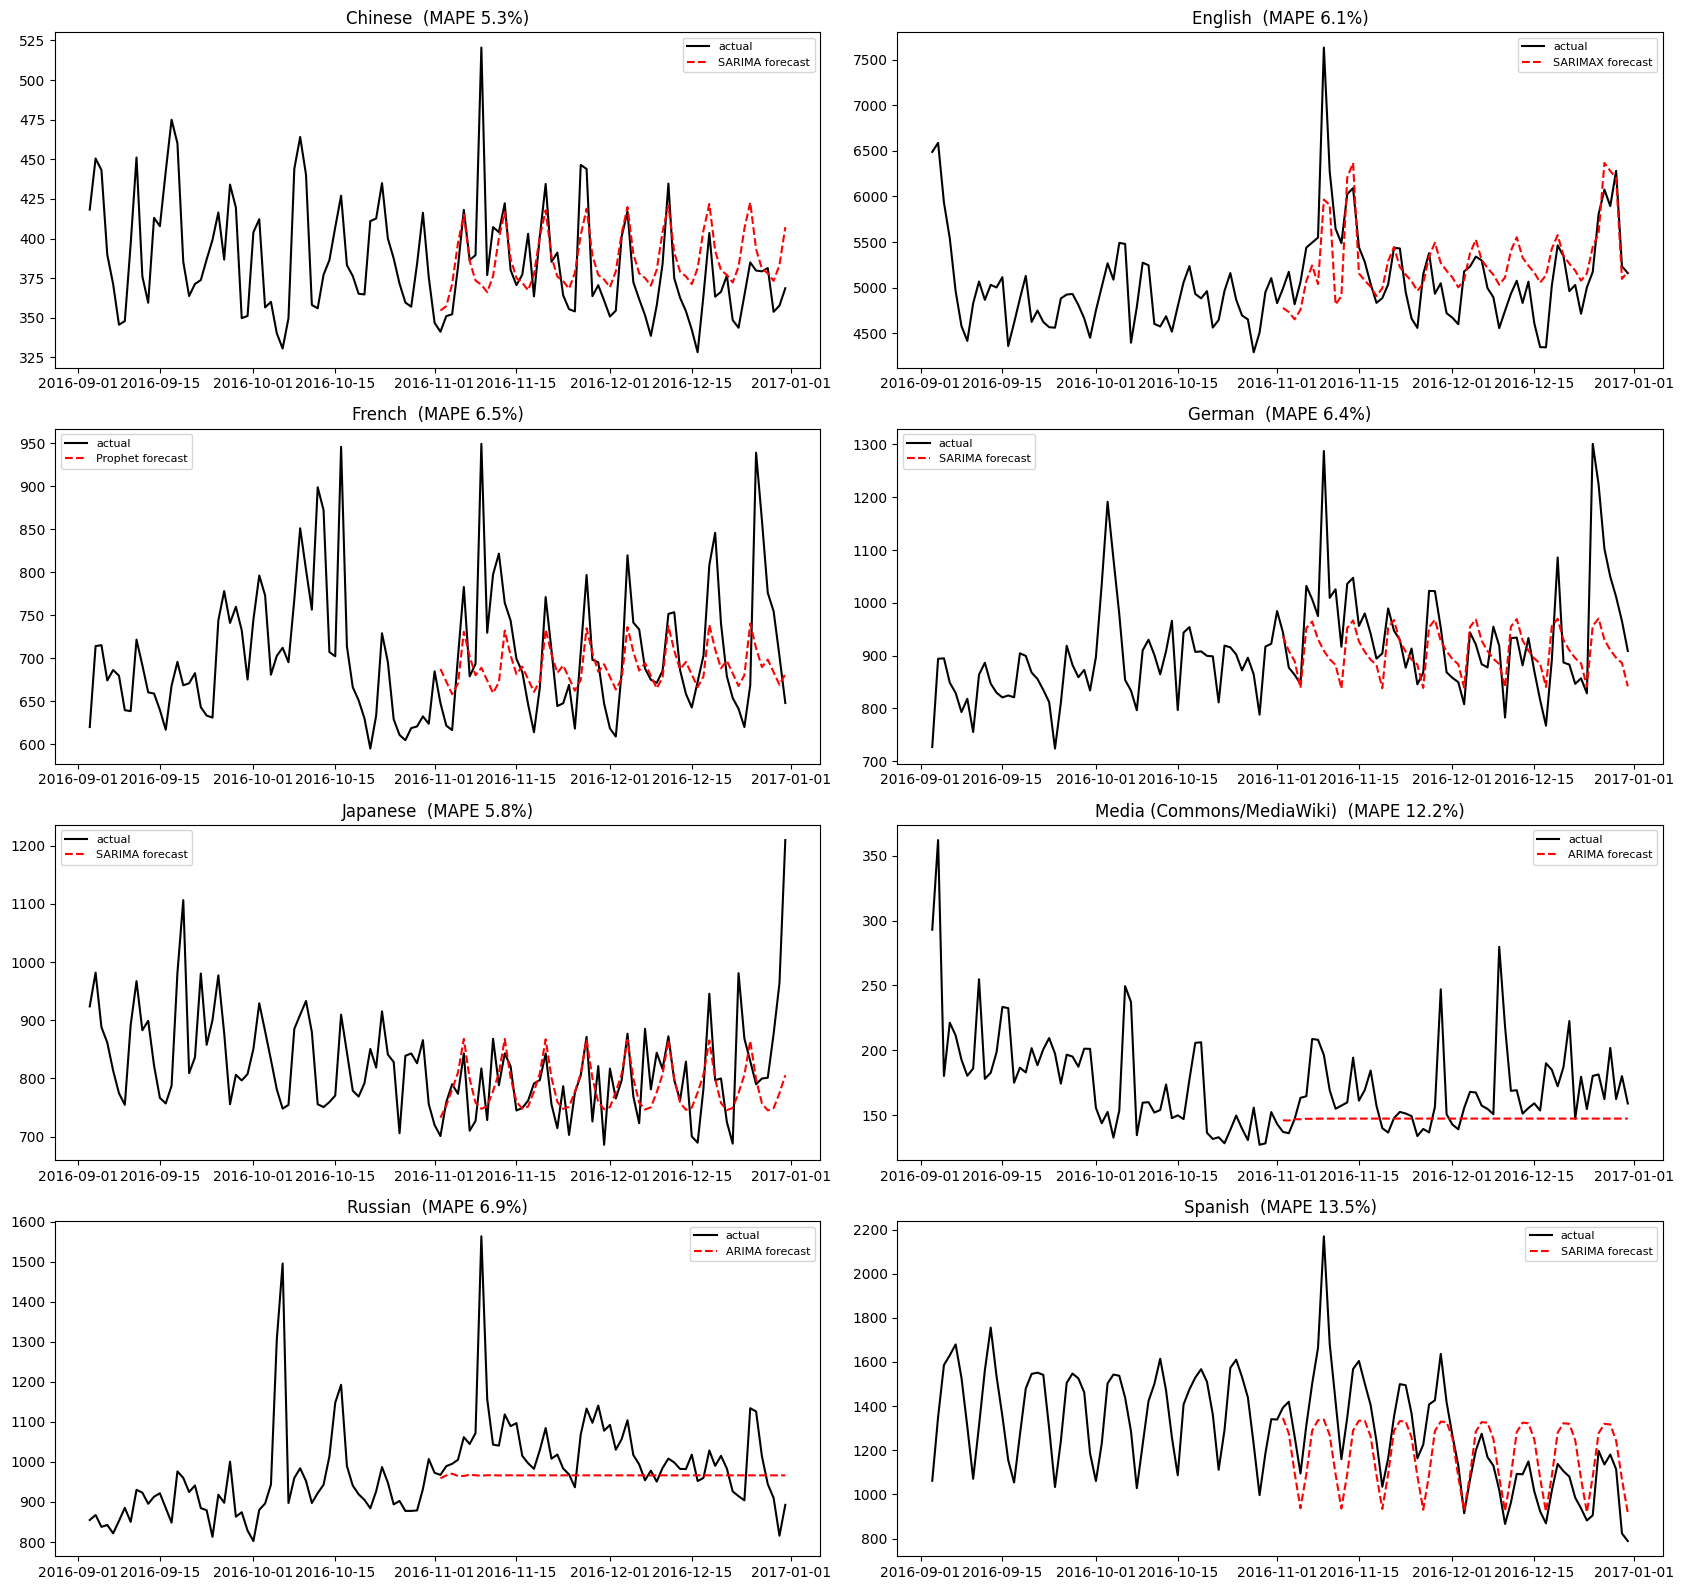

In [100]:
def grid_search(y_train, seasonal=True):
    """Returns the (order, seasonal_order) with the lowest AIC on the training data."""
    PQ = [0, 1] if seasonal else [0]
    best_aic, best = np.inf, None
    for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], PQ, PQ):
        order = (p, 1, q)
        sorder = (P, 1, Q, SEASONAL_PERIOD) if seasonal else (0, 0, 0, 0)
        try:
            aic = SARIMAX(y_train, order=order, seasonal_order=sorder).fit(disp=False).aic
        except Exception:
            continue
        if aic < best_aic:
            best_aic, best = aic, (order, sorder)
    return best


def sarimax_forecast(y_train, order, sorder, ex_train=None, ex_test=None):
    fit = SARIMAX(y_train, exog=ex_train, order=order, seasonal_order=sorder,
                  initialization="approximate_diffuse").fit(disp=False)
    return fit.forecast(steps=TEST_DAYS, exog=ex_test)


def prophet_forecast(y_train, y_test, ex_train=None, ex_test=None):
    train = pd.DataFrame({"ds": y_train.index, "y": y_train.values})
    test = pd.DataFrame({"ds": y_test.index})
    m = Prophet(weekly_seasonality=True, daily_seasonality=False, yearly_seasonality=False)
    if ex_train is not None:
        train["exog"], test["exog"] = ex_train.values, ex_test.values
        m.add_regressor("exog")
    m.fit(train)
    return pd.Series(m.predict(test)["yhat"].values, index=y_test.index)


def run_language(lang):
    """Fits every model for one language and score it on the last TEST_DAYS days."""
    y = lang_mean[lang]
    y_train, y_test = y[:-TEST_DAYS], y[-TEST_DAYS:]
    use_exog = (lang == "English")            # campaign variable exists for English only
    ex_train, ex_test = (exog[:-TEST_DAYS], exog[-TEST_DAYS:]) if use_exog else (None, None)

    preds, params = {}, {}
    # baseline
    preds["SeasonalNaive"] = pd.Series(np.resize(y_train[-SEASONAL_PERIOD:].values, TEST_DAYS), index=y_test.index)

    params["ARIMA"] = grid_search(y_train, seasonal=False)
    preds["ARIMA"] = sarimax_forecast(y_train, *params["ARIMA"])

    params["SARIMA"] = grid_search(y_train)
    preds["SARIMA"] = sarimax_forecast(y_train, *params["SARIMA"])

    if use_exog:
        preds["SARIMAX"] = sarimax_forecast(y_train, *params["SARIMA"], ex_train, ex_test)
        preds["Prophet(exog)"] = prophet_forecast(y_train, y_test, ex_train, ex_test)
    preds["Prophet"] = prophet_forecast(y_train, y_test)

    rows = []
    for name, pred in preds.items():
        mae_, rmse_, mape_ = performance(y_test, pred, print_metrics=False)
        rows.append({"language": lang, "model": name, "MAE": mae_, "RMSE": rmse_, "MAPE": mape_})
    return pd.DataFrame(rows), preds, params


# Run for every language
all_results, all_preds, all_params = [], {}, {}
for lang in LANGS:
    print("Running", lang)
    res, all_preds[lang], all_params[lang] = run_language(lang)
    all_results.append(res)

results = pd.concat(all_results, ignore_index=True)

# MAPE by language and model
mape_table = results.pivot(index="language", columns="model", values="MAPE")
display(mape_table.style.highlight_min(axis=1, color="lightgreen")
        .set_caption("Test MAPE (%), lower is better"))

# Best model per language, compared with the naive baseline
best = (results[results.model != "SeasonalNaive"]
        .sort_values("MAPE").groupby("language").first()[["model", "MAPE", "RMSE"]])
best["naive_MAPE"] = results[results.model == "SeasonalNaive"].set_index("language")["MAPE"]
best["gain_vs_naive_%"] = (1 - best["MAPE"] / best["naive_MAPE"]) * 100
best["within_4_8%"] = best["MAPE"].between(4, 8) | (best["MAPE"] < 4)
display(best.round(2))

# Orders- chosen by the grid search
display(pd.DataFrame({l: {m: v for m, v in p.items()} for l, p in all_params.items()}).T)

# Forecast plots using each language's best model
fig, axes = plt.subplots(4, 2, figsize=(17, 16))
for ax, lang in zip(axes.ravel(), LANGS):
    y = lang_mean[lang]
    ax.plot(y.iloc[-(TEST_DAYS + 60):], "k", label="actual")
    ax.plot(all_preds[lang][best.loc[lang, "model"]], "r--",
            label=f"{best.loc[lang, 'model']} forecast")
    ax.set_title(f"{lang}  (MAPE {best.loc[lang, 'MAPE']:.1f}%)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Results: comparison across languages

Orders were chosen by grid search on AIC using training data only. Every model is scored on the same last 60 days, against a seasonal-naive baseline (repeat the last observed week).

| Language | Best model | MAPE % | Seasonal-naive MAPE % | Gain vs naive |
|---|---|---|---|---|
| Chinese | SARIMA | 5.27 | 4.50 | -17% |
| English | SARIMAX | 6.06 | 9.22 | 34% |
| French | Prophet | 6.48 | 11.14 | 42% |
| German | SARIMA | 6.43 | 7.50 | 14% |
| Japanese | SARIMA | 5.76 | 7.41 | 22% |
| Russian | ARIMA | 6.93 | 10.05 | 31% |
| Media (Commons/MediaWiki) | ARIMA | 12.22 | 16.47 | 26% |
| Spanish | SARIMA | 13.48 | 16.77 | 20% |

Observations:
1. Six of eight languages fall inside the 4-8% MAPE range. Spanish (13.5%) and Media (12.2%) do not.
2. Spanish is hard because the test window (November-December) contains the highest day of the whole series (9 November) and the December drop in level. The forecast misses that spike and keeps the autumn weekly swing while actual views fall. The data covers only 1.5 years, so a yearly pattern cannot be identified.
3. Chinese: the seasonal-naive baseline (4.50%) beats every fitted model. The series is flat and stable, so a model adds nothing.
4. Russian and Media were best fitted by ARIMA, which gives an almost flat forecast. Their errors come from unforecastable spikes rather than from the weekly cycle.

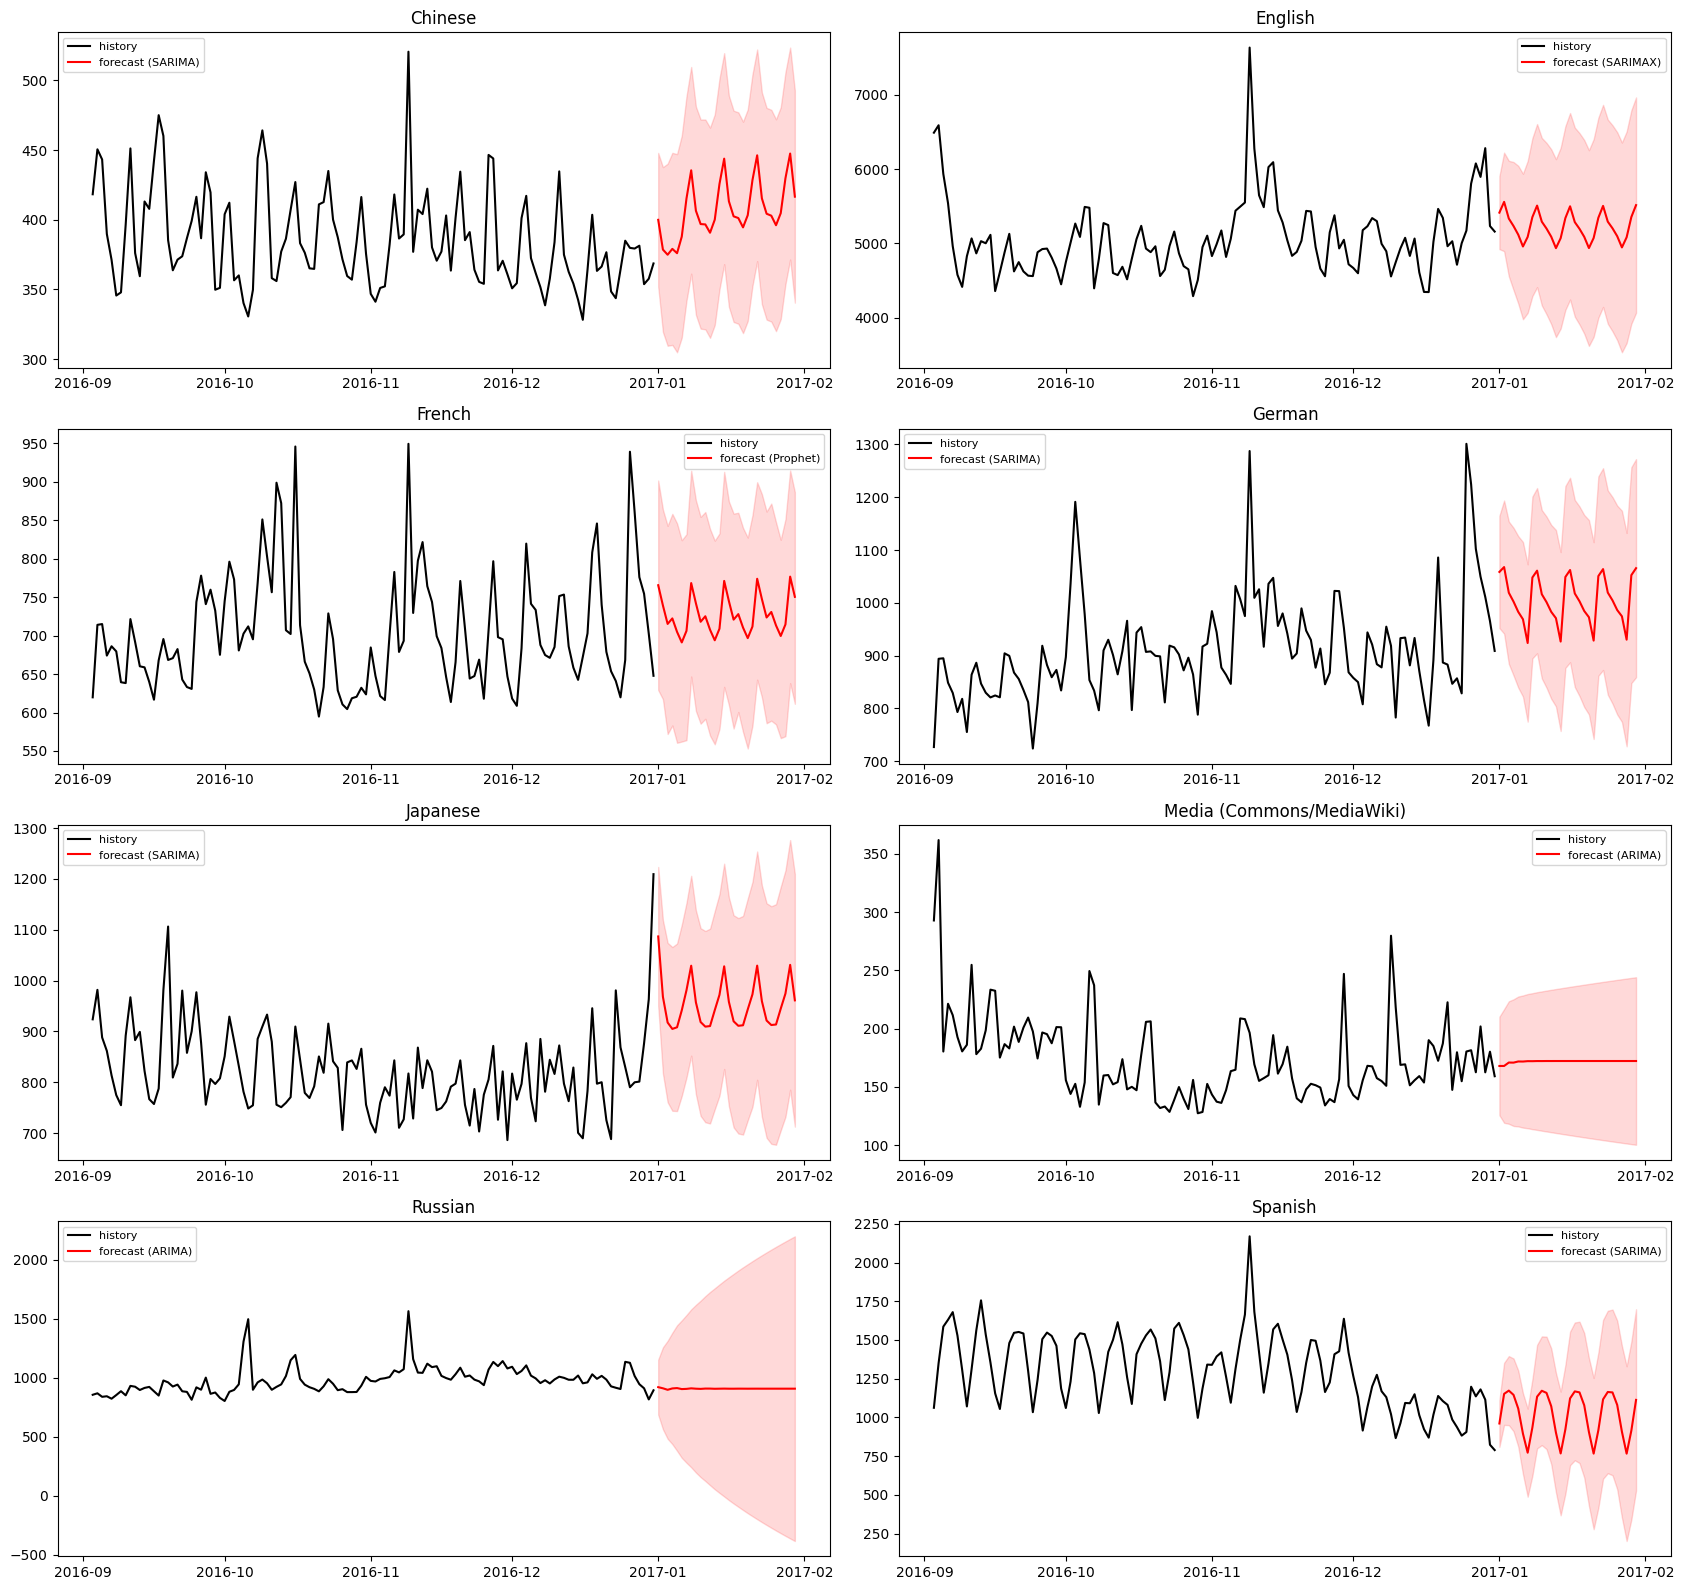

In [101]:
HORIZON = 30
future_idx = pd.date_range(lang_mean.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
future_exog = pd.Series(0, index=future_idx)


def forecast_future(lang, model):

    y = lang_mean[lang]

    if model.startswith("Prophet"):
        train = pd.DataFrame({"ds": y.index, "y": y.values})
        future = pd.DataFrame({"ds": future_idx})
        m = Prophet(weekly_seasonality=True, daily_seasonality=False,
                    yearly_seasonality=False, interval_width=0.95)
        if model == "Prophet(exog)":
            train["exog"], future["exog"] = exog.values, future_exog.values
            m.add_regressor("exog")
        m.fit(train)
        out = m.predict(future)
        pred = pd.Series(out["yhat"].values, index=future_idx)
        ci = pd.DataFrame({"lower": out["yhat_lower"].values,
                           "upper": out["yhat_upper"].values}, index=future_idx)
        return pred, ci

    # ARIMA / SARIMA / SARIMAX: reusing the orders found by the grid search
    params = all_params[lang]
    order, sorder = params["ARIMA"] if model == "ARIMA" else params["SARIMA"]
    use_exog = (model == "SARIMAX")

    fit = SARIMAX(y, exog=exog.values if use_exog else None,
                  order=order, seasonal_order=sorder,
                  initialization="approximate_diffuse").fit(disp=False)
    fc = fit.get_forecast(HORIZON, exog=future_exog.values if use_exog else None)
    pred = pd.Series(fc.predicted_mean.values, index=future_idx)
    ci = pd.DataFrame(fc.conf_int().values, columns=["lower", "upper"], index=future_idx)
    return pred, ci


# Forecasting with the best model of each language
future = {lang: forecast_future(lang, row["model"]) for lang, row in best.iterrows()}

# Plot
n_rows = int(np.ceil(len(best) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(17, 4 * n_rows))
for ax, lang in zip(axes.ravel(), best.index):
    pred, ci = future[lang]
    ax.plot(lang_mean[lang].iloc[-120:], "k", label="history")
    ax.plot(pred, "r", label=f"forecast ({best.loc[lang, 'model']})")
    ax.fill_between(ci.index, ci["lower"], ci["upper"], color="r", alpha=.15)
    ax.set_title(lang)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(best):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

## Insights and recommendations

Insights
- English carries 55.6% of all views and responds strongly to campaigns, so it is the main inventory for ad placement. Modelling it with the campaign variable cuts the error by about a quarter.
- All languages have a weekly cycle, so forecasts must be made per language and per day of the week, not as a flat average.
- Large unexplained spikes (Russian, French, Chinese, Japanese) are the main source of forecast error outside English.

Recommendations
1. Use the best model for each language rather than one model for all: SARIMAX for English, SARIMA for Chinese, German, Japanese and Spanish, Prophet for French and ARIMA for Russian and Media. Use the seasonal-naive forecast for Chinese until a model beats it.
2. Plan English ad budgets around known campaign dates. Set `future_exog` to 1 on planned campaign days to see their effect on the 30-day forecast.
3. Collect event/campaign flags for the other languages (for example the Russian summer 2016 and French April 2016 spikes). They are the largest source of error and could be used as exogenous variables the way English is.
4. For Spanish and Media, should try log transformation. A longer history would also let yearly seasonality be modelled.
5. Quote forecasts with their 95% intervals, which widen with the horizon, and retrain every few weeks as new data arrives.

## Questionnaire

**What does decomposition do?**
It splits a series into trend, seasonality and residual. For English it shows a slowly rising trend with a large surge in summer 2016, a stable weekly pattern, and residuals that grow during the campaign surge. This guides the choice of differencing and seasonal terms and shows where unusual events sit.

**Which level of differencing gave a stationary series?**
By the ADF test, Chinese, English and German need d = 1 (levels are not stationary), and the other five languages are already stationary at d = 0 (though only just for French, Japanese and Spanish). Because the weekly cycle is strong, the SARIMA models use d = 1 and D = 1 with s = 7. For English, d = 1 and also d = 1 with D = 1 are stationary (p < 0.0001).

**ARIMA vs SARIMA vs SARIMAX**
- ARIMA(p,d,q): autoregressive and moving-average terms plus differencing, with no seasonal component.
- SARIMA(p,d,q)(P,D,Q,s): ARIMA plus seasonal terms, which capture the weekly cycle (s = 7).
- SARIMAX: SARIMA plus external regressors, here the campaign flag. It improved English MAPE from 8.15% to 6.10%.

**Number of views by language.**
English is far ahead with about 4,700 views per page per day (55.6% of all views), followed by Spanish (about 1,280), Russian (1,060), German (940), Japanese (880), French (670), Chinese (370) and Media (146). By total views Spanish, Japanese and German are each about 8.5-8.9% of the total, French is 5.9%, Chinese 3.1% and Media 1.3%.

**Methods other than grid search.**
- Automatic stepwise search is much faster.
- Random search or Bayesian optimisation (for example Optuna) samples the space instead of trying every combination.
- ACF/PACF-guided search narrows the candidate orders.
- Rolling-origin cross-validation gives a more reliable error estimate.
- A global model (one model trained across all languages, for example LightGBM or a neural forecaster) avoids fitting eight separate models.